In [1]:
import os
import sys
import time
import pickle
import warnings
warnings.filterwarnings("ignore")
sys.path.append("/path/to/GeneSPOT")

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
from tqdm import tqdm
import spatialdata as sd
import spatialdata_plot
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [2]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything, filter_extreme_values
from vendor.niche_embedding.MENDER import Mender
from genespot.preprocess import preprocess_adata, concat_features
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import create_cmap
from genespot.visualization import create_cmap, soview

random_state = 42
seed_everything(random_state)

cmap_r = create_cmap(['white', 'red'])
cmap_g = create_cmap(['white', 'green'])
cmap_b = create_cmap(['white', 'blue'])
cmap_rbgs = [cmap_r, cmap_g, cmap_b]

In [3]:
data_dir = Path('/path/to/GeneSPOT/data/xenium_hbc')
res_dir = Path('/path/to/GeneSPOT/reproduce/supp/xenium_hbc/res')

os.makedirs(res_dir, exist_ok=True)

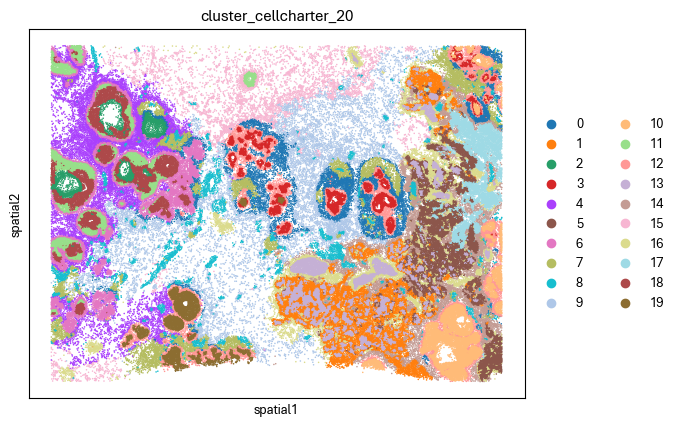

In [4]:
rep1_adata = sc.read_h5ad(data_dir / 'rep1_adata.h5ad')
genes = rep1_adata.var_names.tolist()
rep1_adata.var['feature_names'] = rep1_adata.var_names.tolist()

import pickle

cc_layer = 3
scvi_ = 'scvi_inte'
with open(res_dir / f'{scvi_}/layer{cc_layer}/X_cellcharter.pkl', 'rb') as f:
    rep1_adata.obsm['X_cellcharter'] = pickle.load(f)
with open(res_dir / f'{scvi_}/X_scVI.pkl', 'rb') as f:
    rep1_adata.obsm['X_scVI'] = pickle.load(f)

for k in range(2, 20+1):
    rep1_adata.obs[f'cluster_cellcharter_{k}'] = pd.read_csv(res_dir / f'{scvi_}/layer{cc_layer}/cluster_cellcharter_{k}.csv', index_col=0).values
    rep1_adata.obs[f'cluster_cellcharter_{k}'] = rep1_adata.obs[f'cluster_cellcharter_{k}'].astype('category')

ax = sc.pl.embedding(rep1_adata, basis='spatial', color='cluster_cellcharter_20', size=5, show=False)
ax.invert_xaxis()
plt.show()

In [5]:
graph_start_time = time.time()
cost, running_adata = build_graph(
    rep1_adata,
    coarsen=True, coarsen_key='cluster_cellcharter_20',
    
    feature_expression_layer='raw', 
    feature_aggregate_func='mean',
    
    add_landmarks=True,
    landmark_key='cluster_cellcharter',
    landmark_expression_value=1.,
    non_landmark_expression_value=0.,
    landmark_prefix='SpatialLandmark',
    
    n_neighbors=15,
    use_rep='X_cellcharter',
    coarsen_method='paga_guided_umap',
    random_state=random_state,
    connect_threshold=0.
)
graph_time = time.time() - graph_start_time

distance_start_time = time.time()
gstd = cal_ot_distance(running_adata.X, cost, processes=None)
distance_time = time.time() - distance_start_time
ffdistance = pd.DataFrame(gstd, index=running_adata.var['feature_names'], columns=running_adata.var['feature_names'])

embedding_start_time = time.time()
feature_embedding, _, loss = node2vec(
    gstd, 
    n_neighbors=10,
    p=1, q=0.5,
    epochs=400,
    lr=1e-2,
    walk_length=10,
    context_size=10,
    device='cpu',
    workers=1,
    norm=True
)
embedding_time = time.time() - embedding_start_time
print(f'Graph time: {graph_time:.4f}s')
print(f'Distance time: {distance_time:.4f}s')
print(f'Embedding time: {embedding_time:.4f}s')
print(f'Total: {graph_time+distance_time+embedding_time:.4f}s')

gdata = sc.AnnData(running_adata.X.T)
gdata.obsm['feature_embedding'] = feature_embedding
gdata.obs_names = running_adata.var['feature_names']
gdata.obs['feature_names'] = running_adata.var['feature_names']
gdata.obs['feature_types'] = running_adata.var['feature_types']
gdata.obs['feature_annotations'] = running_adata.var['feature_annotations']

gdata.uns['cost'] = cost
gdata.uns['ffdistance'] = ffdistance
gdata.uns['running_adata'] = running_adata
sc.pp.neighbors(gdata, use_rep='feature_embedding')
sc.tl.umap(gdata)
sc.tl.leiden(gdata, resolution=4)

Training: 100%|██████████| 400/400 [05:21<00:00,  1.24it/s, loss=2.96]


Graph time: 111.4419s
Distance time: 8.5496s
Embedding time: 323.6879s
Total: 443.6794s


In [5]:
graph_start_time = time.time()
cost, running_adata = build_graph(
    rep1_adata,
    coarsen=True, coarsen_key='cluster_cellcharter_20',
    
    feature_expression_layer='raw', 
    feature_aggregate_func='mean',
    
    add_landmarks=True,
    landmark_key='cluster_cellcharter',
    landmark_expression_value=1.,
    non_landmark_expression_value=0.,
    landmark_prefix='SpatialLandmark',
    
    n_neighbors=15,
    use_rep='X_cellcharter',
    coarsen_method='paga_guided_umap',
    random_state=random_state,
    connect_threshold=0.
)
graph_time = time.time() - graph_start_time

distance_start_time = time.time()
gstd = cal_ot_distance(running_adata.X, cost, processes=None)
distance_time = time.time() - distance_start_time
ffdistance = pd.DataFrame(gstd, index=running_adata.var['feature_names'], columns=running_adata.var['feature_names'])

embedding_start_time = time.time()
feature_embedding, _, loss = node2vec(
    gstd, 
    n_neighbors=10,
    p=1, q=0.5,
    epochs=400,
    lr=1e-2,
    walk_length=10,
    context_size=10,
    device='cuda:0',
    workers=1,
    norm=True
)
embedding_time = time.time() - embedding_start_time
print(f'Graph time: {graph_time:.4f}s')
print(f'Distance time: {distance_time:.4f}s')
print(f'Embedding time: {embedding_time:.4f}s')
print(f'Total: {graph_time+distance_time+embedding_time:.4f}s')

gdata = sc.AnnData(running_adata.X.T)
gdata.obsm['feature_embedding'] = feature_embedding
gdata.obs_names = running_adata.var['feature_names']
gdata.obs['feature_names'] = running_adata.var['feature_names']
gdata.obs['feature_types'] = running_adata.var['feature_types']
gdata.obs['feature_annotations'] = running_adata.var['feature_annotations']

gdata.uns['cost'] = cost
gdata.uns['ffdistance'] = ffdistance
gdata.uns['running_adata'] = running_adata
sc.pp.neighbors(gdata, use_rep='feature_embedding')
sc.tl.umap(gdata)
sc.tl.leiden(gdata, resolution=4)

Training: 100%|██████████| 400/400 [00:41<00:00,  9.52it/s, loss=2.96]


Graph time: 114.1537s
Distance time: 8.6111s
Embedding time: 45.2050s
Total: 167.9697s
